In [9]:
!pip install -q pandas numpy matplotlib seaborn scikit-learn==1.6.1 Sastrawi nltk tqdm


In [10]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from tqdm.notebook import tqdm

from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Scikit-learn:", __import__("sklearn").__version__)


Scikit-learn: 1.6.1


In [11]:
url = "https://raw.githubusercontent.com/DorberkWilliamFreivar/pre-project_Pengembangan-Sistem-Deteksi-Ujaran-Kebencian-Berbahasa-Indonesia-/main/re_dataset.csv"

df = pd.read_csv(url, encoding="latin-1")

print("Dataset berhasil dimuat.")
print("Ukuran dataset:", df.shape)
print("Kolom:", df.columns.tolist())
display(df.head())


Dataset berhasil dimuat.
Ukuran dataset: (13169, 13)
Kolom: ['Tweet', 'HS', 'Abusive', 'HS_Individual', 'HS_Group', 'HS_Religion', 'HS_Race', 'HS_Physical', 'HS_Gender', 'HS_Other', 'HS_Weak', 'HS_Moderate', 'HS_Strong']


,Tweet,HS,Abusive,HS_Individual,HS_Group,HS_Religion,HS_Race,HS_Physical,HS_Gender,HS_Other,HS_Weak,HS_Moderate,HS_Strong
0,- disaat semua cowok berusaha melacak perhatia...,1,1,1,0,0,0,0,0,1,1,0,0
1,RT USER: USER siapa yang telat ngasih tau elu?...,0,1,0,0,0,0,0,0,0,0,0,0
2,"41. Kadang aku berfikir, kenapa aku tetap perc...",0,0,0,0,0,0,0,0,0,0,0,0
3,USER USER AKU ITU AKU\n\nKU TAU MATAMU SIPIT T...,0,0,0,0,0,0,0,0,0,0,0,0
4,USER USER Kaum cebong kapir udah keliatan dong...,1,1,0,1,1,0,0,0,0,0,1,0


In [12]:
if "Class" not in df.columns:
    def buat_class(row):
        hs = int(row["HS"])
        abusive = int(row["Abusive"])

        if hs == 0 and abusive == 0:
            return "NON_HS_NON_ABUSIVE"
        elif hs == 1 and abusive == 0:
            return "HS"
        elif hs == 0 and abusive == 1:
            return "ABUSIVE"
        else:
            return "HS_AND_ABUSIVE"

    df["Class"] = df.apply(buat_class, axis=1)

print(df["Class"].value_counts())


Class
NON_HS_NON_ABUSIVE    5860
HS_AND_ABUSIVE        3295
HS                    2266
ABUSIVE               1748
Name: count, dtype: int64


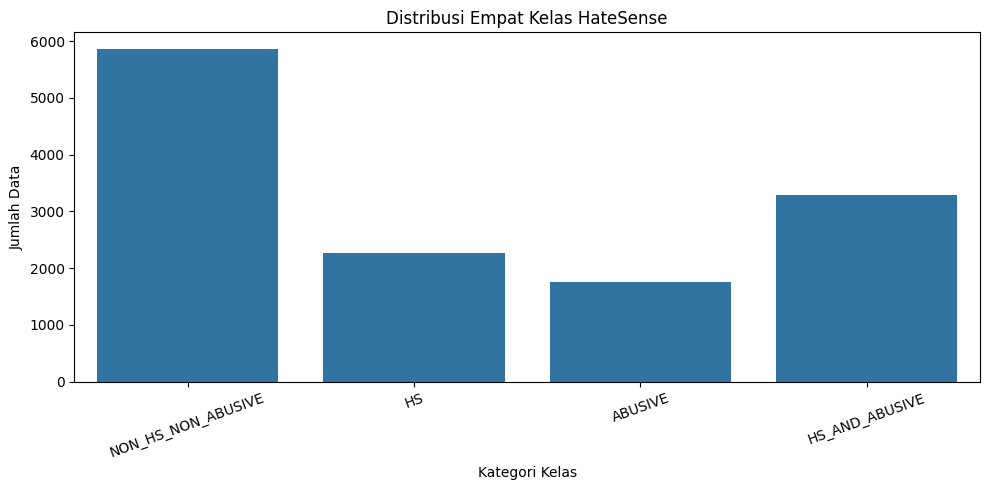

In [13]:
urutan_kelas = [
    "NON_HS_NON_ABUSIVE",
    "HS",
    "ABUSIVE",
    "HS_AND_ABUSIVE"
]

plt.figure(figsize=(10, 5))
sns.countplot(data=df, x="Class", order=urutan_kelas)
plt.title("Distribusi Empat Kelas HateSense")
plt.xlabel("Kategori Kelas")
plt.ylabel("Jumlah Data")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


In [14]:
factory = StemmerFactory()
stemmer = factory.create_stemmer()

stop_factory = StopWordRemoverFactory()
stopwords = set(stop_factory.get_stop_words())

# Mempertahankan kata negasi
negation_words = {"tidak", "bukan", "jangan", "belum", "tanpa"}
stopwords = stopwords - negation_words

normalisasi = {
    "gak": "tidak",
    "ga": "tidak",
    "nggak": "tidak",
    "enggak": "tidak",
    "tdk": "tidak",
    "yg": "yang",
    "dgn": "dengan",
    "krn": "karena",
    "aja": "saja",
    "udah": "sudah",
    "blm": "belum",
    "bgt": "banget",
    "kalo": "kalau",
    "loe": "kamu",
    "lu": "kamu",
    "gw": "saya",
    "gue": "saya"
}

print("Inisialisasi preprocessing selesai.")


Inisialisasi preprocessing selesai.


## 7. Fungsi preprocessing
Urutan tahapan dipertahankan sesuai implementasi sebelumnya.

In [15]:
def preprocessing(text):
    if pd.isna(text):
        return ""

    text = str(text)

    # Cleaning
    text = re.sub(r"http\S+|www\\S+", " ", text)
    text = re.sub(r"@\w+", " ", text)
    text = re.sub(r"RT\s+", " ", text)

    # Case folding
    text = text.lower()

    # Menghapus simbol dan angka
    text = re.sub(r"[^a-zA-Z\\s]", " ", text)

    # Tokenisasi
    tokens = text.split()

    # Normalisasi
    tokens = [normalisasi.get(word, word) for word in tokens]

    # Stopword removal
    tokens = [
        word for word in tokens
        if word not in stopwords and len(word) > 1
    ]

    # Stemming
    tokens = [stemmer.stem(word) for word in tokens]

    return " ".join(tokens)

# Tes fungsi pada beberapa kalimat, hanya memproses contoh ini
contoh_teks = [
    "Kamu jangan gitu, itu salah tau",
    "Kamu baik sekali hari ini"
]

for teks in contoh_teks:
    print(teks, "->", preprocessing(teks))


Kamu jangan gitu, itu salah tau -> kamu jangan gitu salah tau
Kamu baik sekali hari ini -> kamu baik sekali hari


## 8. Preprocessing seluruh dataset

**Cell ini paling lama.** Proses setiap tweet satu kali. Jangan menjalankan ulang jika sudah selesai dan `Tweet_clean` masih tersedia.


In [16]:
tqdm.pandas()

df["Tweet_clean"] = df["Tweet"].progress_apply(preprocessing)

display(df[["Tweet", "Tweet_clean", "Class"]].head())
print("Preprocessing selesai.")


  0%|          | 0/13169 [00:00<?, ?it/s]

,Tweet,Tweet_clean,Class
0,- disaat semua cowok berusaha melacak perhatia...,saat semua cowok usaha lacak perhati kamu lant...,HS_AND_ABUSIVE
1,RT USER: USER siapa yang telat ngasih tau elu?...,user user siapa telat ngasih tau elu edan sara...,ABUSIVE
2,"41. Kadang aku berfikir, kenapa aku tetap perc...",kadang aku berfikir aku tetap percaya tuhan pa...,NON_HS_NON_ABUSIVE
3,USER USER AKU ITU AKU\n\nKU TAU MATAMU SIPIT T...,user user aku aku n nku tau mata sipit liat ma...,NON_HS_NON_ABUSIVE
4,USER USER Kaum cebong kapir udah keliatan dong...,user user kaum cebong kapir liat dongok awal t...,HS_AND_ABUSIVE


Preprocessing selesai.


## 9. Membersihkan hasil preprocessing

In [17]:
df = df.dropna(subset=["Tweet_clean", "Class"]).copy()
df = df[df["Tweet_clean"].str.strip() != ""].copy()
df = df.reset_index(drop=True)

print("Jumlah data setelah preprocessing:", len(df))
print("Jumlah Tweet_clean kosong:", (df["Tweet_clean"].str.strip() == "").sum())


Jumlah data setelah preprocessing: 13169
Jumlah Tweet_clean kosong: 0


## 10. Menentukan fitur dan label

In [18]:
X = df["Tweet_clean"]
y = df["Class"]

class_names = [
    "NON_HS_NON_ABUSIVE",
    "HS",
    "ABUSIVE",
    "HS_AND_ABUSIVE"
]

print(y.value_counts())


Class
NON_HS_NON_ABUSIVE    5860
HS_AND_ABUSIVE        3295
HS                    2266
ABUSIVE               1748
Name: count, dtype: int64


## 11. Train-test split (80:20)

In [19]:
# Simpan indeks agar tweet asli dapat ditelusuri saat analisis kesalahan
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Data training:", len(X_train))
print("Data testing:", len(X_test))


Data training: 10535
Data testing: 2634


## 12. TF-IDF

In [20]:
tfidf = TfidfVectorizer(
    max_features=10000,
    ngram_range=(1, 2),
    min_df=2
)

X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

print("Matriks training:", X_train_tfidf.shape)
print("Matriks testing:", X_test_tfidf.shape)


Matriks training: (10535, 10000)
Matriks testing: (2634, 10000)


## 13. Mendefinisikan empat model

In [21]:
models = {
    "Naive Bayes": MultinomialNB(),

    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "SVM": LinearSVC(
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced_subsample",
        random_state=42,
        n_jobs=-1
    )
}

print("Model yang akan diuji:", list(models.keys()))


Model yang akan diuji: ['Naive Bayes', 'Logistic Regression', 'SVM', 'Random Forest']


## 14. Training empat model

Random Forest pada data TF-IDF dapat memerlukan waktu dan memori lebih besar. Tunggu sampai semua model selesai dilatih.


In [22]:
trained_models = {}

for name, model in models.items():
    print(f"Sedang melatih {name}...")
    model.fit(X_train_tfidf, y_train)
    trained_models[name] = model
    print(f"{name} selesai.")

print("Semua model selesai dilatih.")


Sedang melatih Naive Bayes...
Naive Bayes selesai.
Sedang melatih Logistic Regression...
Logistic Regression selesai.
Sedang melatih SVM...
SVM selesai.
Sedang melatih Random Forest...
Random Forest selesai.
Semua model selesai dilatih.


## 15. Perbandingan metrik evaluasi
Precision, recall, dan F1-score dihitung dengan `average='macro'` agar setiap kelas mendapat bobot yang sama.

In [23]:
results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test_tfidf)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, average="macro", zero_division=0
        ),
        "F1-Score": f1_score(
            y_test, y_pred, average="macro", zero_division=0
        )
    })

hasil_evaluasi = pd.DataFrame(results)
display(hasil_evaluasi.round(4))


,Model,Accuracy,Precision,Recall,F1-Score
0,Naive Bayes,0.7494,0.8058,0.6448,0.6817
1,Logistic Regression,0.7768,0.7422,0.7695,0.7519
2,SVM,0.7904,0.7600,0.7644,0.7615
3,Random Forest,0.7802,0.7717,0.7319,0.7480


## 16. Classification report setiap model

In [24]:
for name, model in trained_models.items():
    print("\\n" + "=" * 55)
    print("MODEL:", name)
    print("=" * 55)

    y_pred = model.predict(X_test_tfidf)

    print(classification_report(
        y_test,
        y_pred,
        labels=class_names,
        zero_division=0
    ))


\n=======================================================
MODEL: Naive Bayes
                    precision    recall  f1-score   support

NON_HS_NON_ABUSIVE       0.73      0.97      0.83      1172
                HS       0.87      0.51      0.65       453
           ABUSIVE       0.91      0.37      0.53       350
    HS_AND_ABUSIVE       0.71      0.72      0.72       659

          accuracy                           0.75      2634
         macro avg       0.81      0.64      0.68      2634
      weighted avg       0.77      0.75      0.73      2634

\n=======================================================
MODEL: Logistic Regression
                    precision    recall  f1-score   support

NON_HS_NON_ABUSIVE       0.88      0.81      0.85      1172
                HS       0.70      0.83      0.76       453
           ABUSIVE       0.61      0.74      0.67       350
    HS_AND_ABUSIVE       0.78      0.69      0.73       659

          accuracy                           0.78    

## 17. Confusion matrix setiap model

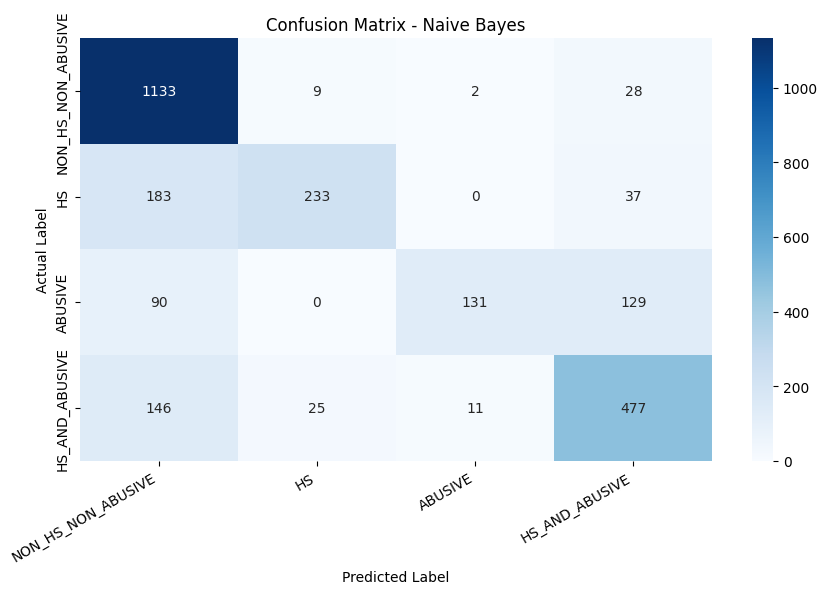

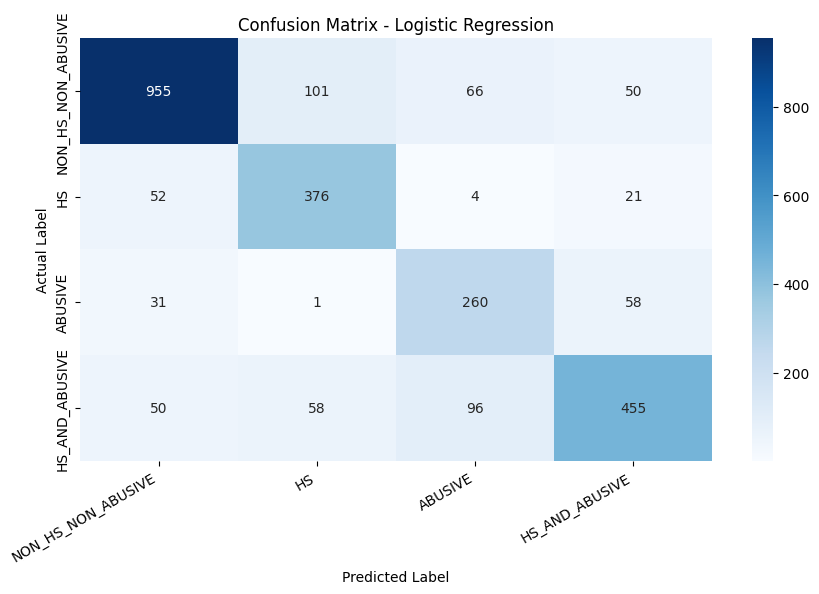

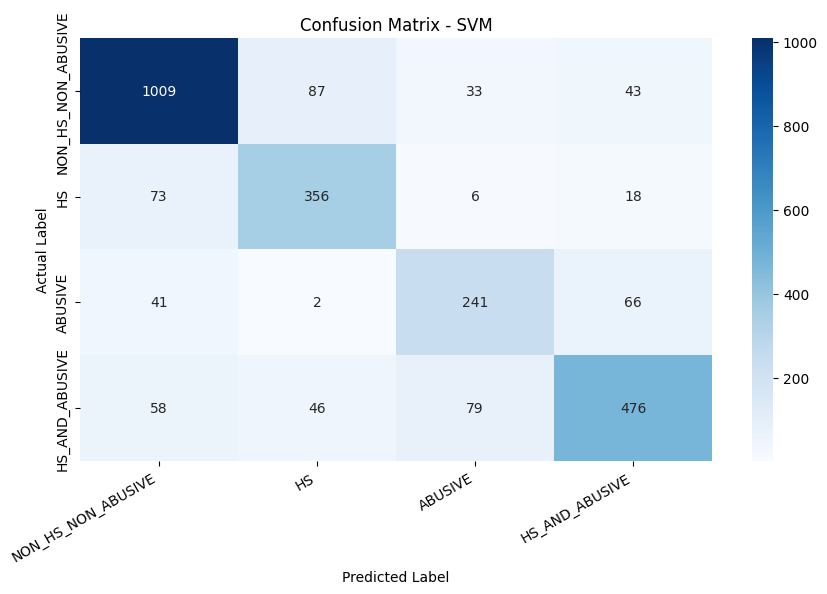

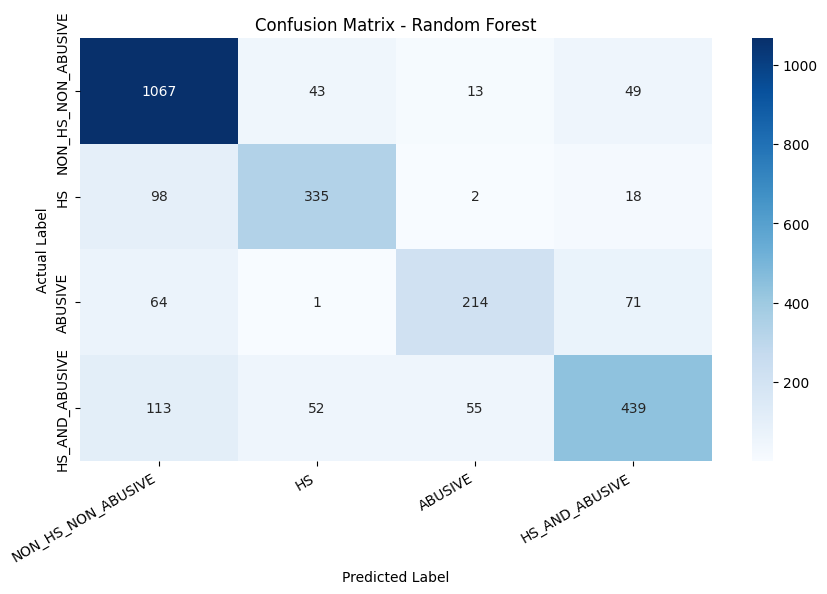

In [25]:
for name, model in trained_models.items():
    y_pred = model.predict(X_test_tfidf)

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_names
    )

    plt.figure(figsize=(9, 6))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=class_names,
        yticklabels=class_names
    )

    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()


## 18. Menentukan model terbaik berdasarkan Macro F1-Score

In [26]:
hasil_ranking = hasil_evaluasi.sort_values(
    by="F1-Score",
    ascending=False
).reset_index(drop=True)

display(hasil_ranking.round(4))

best_model_name = hasil_ranking.loc[0, "Model"]
best_model = trained_models[best_model_name]

print("Model terbaik berdasarkan Macro F1-Score:", best_model_name)


,Model,Accuracy,Precision,Recall,F1-Score
0,SVM,0.7904,0.7600,0.7644,0.7615
1,Logistic Regression,0.7768,0.7422,0.7695,0.7519
2,Random Forest,0.7802,0.7717,0.7319,0.7480
3,Naive Bayes,0.7494,0.8058,0.6448,0.6817


Model terbaik berdasarkan Macro F1-Score: SVM


## 19. Grafik perbandingan empat model

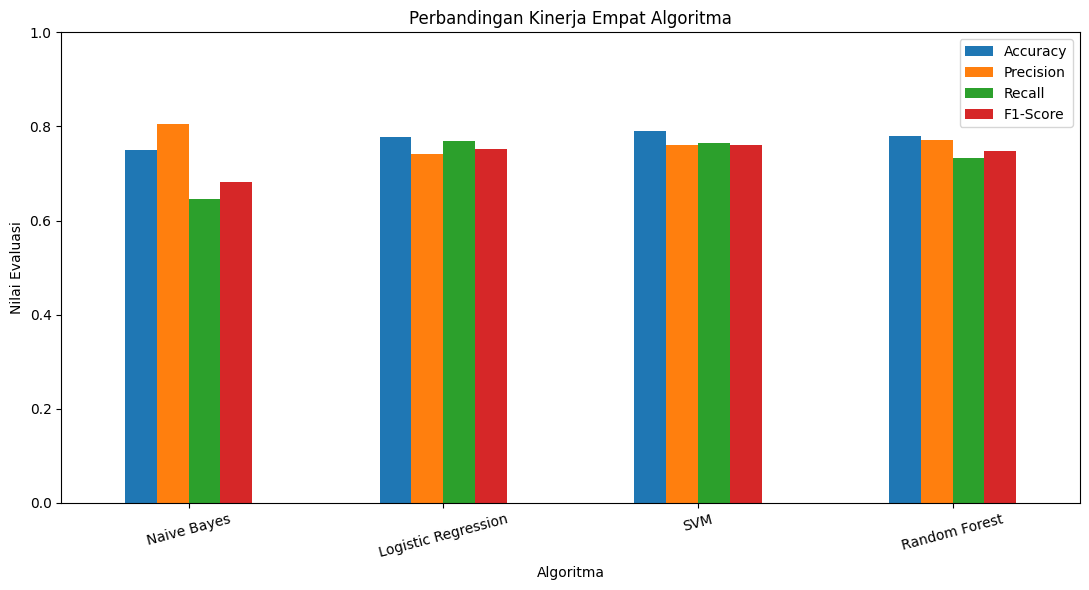

In [27]:
hasil_plot = hasil_evaluasi.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
]

hasil_plot.plot(kind="bar", figsize=(11, 6))
plt.title("Perbandingan Kinerja Empat Algoritma")
plt.ylabel("Nilai Evaluasi")
plt.xlabel("Algoritma")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


## 20. Analisis kesalahan prediksi model terbaik
Mengambil contoh data testing yang salah diklasifikasikan tanpa menjalankan preprocessing ulang.

In [28]:
y_pred_best = best_model.predict(X_test_tfidf)

hasil_prediksi = pd.DataFrame({
    "Tweet": df.loc[X_test.index, "Tweet"].values,
    "Tweet_clean": X_test.values,
    "Actual": y_test.values,
    "Predicted": y_pred_best
})

salah_klasifikasi = hasil_prediksi[
    hasil_prediksi["Actual"] != hasil_prediksi["Predicted"]
].copy()

print("Jumlah salah klasifikasi:", len(salah_klasifikasi))
display(salah_klasifikasi.head(20))


Jumlah salah klasifikasi: 552


,Tweet,Tweet_clean,Actual,Predicted
5,"RT USER: Sudah la BABI , perangai pun BABI\xf0...",user la babi perangai babi xf x f x x xf x f x...,HS_AND_ABUSIVE,ABUSIVE
8,"USER Presiden polling , menang mimpi dan onani'",user presiden polling menang mimpi onani,HS_AND_ABUSIVE,NON_HS_NON_ABUSIVE
10,Orang yg suka merusak generasi muda adalah man...,orang suka rusak generasi muda manusia ateis k...,NON_HS_NON_ABUSIVE,HS
11,Mau rokok g sob? | Gw ga ngerokok men | Ah ban...,mau rokok sob tidak ngerokok men ah banci kamu...,HS_AND_ABUSIVE,ABUSIVE
17,Sinting gua asli anak winner beneran pada puny...,sinting gua asli anak winner beneran punya twi...,ABUSIVE,HS_AND_ABUSIVE
24,Kementerian Keuangan melalui Direktorat Jender...,menteri uang lalu direktorat jenderal pajak dj...,NON_HS_NON_ABUSIVE,HS
28,USER Trus sampah seprti kalian mau jadikan neg...,user trus sampah seprti kalian mau jadi negeri...,HS_AND_ABUSIVE,HS
34,USER artikel buat manusia.tapi yg tidur anjing...,user artikel buat manusia tidur anjing ae kamu...,NON_HS_NON_ABUSIVE,HS_AND_ABUSIVE
42,Seblak = pusing/mencret',seblak pusing mencret,NON_HS_NON_ABUSIVE,ABUSIVE
46,Idih nanya kok terakhir emange mo modar',idih nanya kok akhir emange mo modar,ABUSIVE,HS_AND_ABUSIVE


## 21. Menyimpan model terbaik dan TF-IDF

In [29]:
joblib.dump(best_model, "best_model_hatesense.pkl")
joblib.dump(tfidf, "tfidf_hatesense.pkl")

print("Model terbaik:", best_model_name)
print("File best_model_hatesense.pkl dan tfidf_hatesense.pkl berhasil disimpan.")


Model terbaik: SVM
File best_model_hatesense.pkl dan tfidf_hatesense.pkl berhasil disimpan.


## 22. Download file model

In [30]:
from google.colab import files

files.download("best_model_hatesense.pkl")
files.download("tfidf_hatesense.pkl")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>